## Generate Data from Logical Rules

In [1]:
import math
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
from ANDRE_Net import ANDRE
from collections import Counter
from utils import check_binary_dataset, create_V_matrix
from utils import plot_andre_weights
from utils import interpret_neuron_weights_entropy, interpret_neuron_weights
from utils import compute_acc_ratio_all_rules_attention
from utils import extract_rules
from utils import parse_rule_and_generate_data
import numpy as np

generate_data = True
structured_data = True
if structured_data:
    body_predicates = ["father(X1, X2)", "father(X2, X3)", "father(X1, X3)", "mother(X1, X2)", "mother(X2, X3)", "mother(X1, X3)"]
    head_predicate = "grandparent(X1, X3)"
    variable_matrix, variables = create_V_matrix(body_predicates)
    head_vars = [0, 2]
    connected_vars = [1]
else:
    variable_matrix, variables = None, None
    body_predicates = None
    head_predicate = None

# Parameters
Num_rules = 4
num_samples = 128
num_epochs = 500
num_restarts = 5
batch_size = 128
sim_weight, ent_weight, rr_weight, conn_weight = 0.1, 1, 0.01, 2

seed = 42
visualize_weights = True

if generate_data:

    if not structured_data:
        input_dim = 5
        body_predicates = [f"b{i+1}" for i in range(input_dim)]
        head_predicate = "h"
    else:
        input_dim = len(body_predicates)
        body_predicates = body_predicates
        head_predicate = head_predicate

    dataset_type = "binary"
    # dataset_type = "continuous"
    
    # Generate Random Dataset
    torch.manual_seed(seed)
    if dataset_type == "binary":
        X_train = (torch.rand(num_samples, input_dim) > 0.5).float()
        acc_threshold = 0.999
    else:
        X_train = torch.rand(num_samples, input_dim)
        acc_threshold = 0.999

    if check_binary_dataset(X_train):
        print("X_train is a binary dataset. We are perturbing the data for better training.")
        # perturb data by adding small noise to zero and reducing one to less than one
        X_train = X_train - 0.1 * torch.rand_like(X_train) * (X_train - 0.5).sign()
        # clip to [0, 1]
        X_train = torch.clamp(X_train, 0.0, 1.0)
        
    # y_train = (((X_train[:, 0] > 0.5) & ((1 - X_train[:, 9]) > 0.5)) | ((X_train[:, 1] > 0.5) & (X_train[:, 8] > 0.5)) | 
    #            ((X_train[:, 2] > 0.5) & (X_train[:, 7] > 0.5))).float()

    # Fix: ensure each arithmetic expression is compared before using bitwise AND/OR.
    # Without proper parentheses a float tensor can be used with '&' which raises the runtime error.
    # y_train = (
    #     (
    #         (X_train[:, 0] > 0.5) & ((1 - X_train[:, 5]) > 0.5) & (X_train[:, 9] > 0.5)
    #     )
    #     |
    #     (
    #         ((1 - X_train[:, 2]) > 0.5) & ((1 - X_train[:, 4]) > 0.5) & (X_train[:, 8] > 0.5)
    #     )
    # ).float()

    y_train = (((X_train[:, 0] > 0.5) & (X_train[:, 1] > 0.5)) | 
            ((X_train[:, 0] > 0.5) & (X_train[:, 4] > 0.5)) | 
            ((X_train[:, 3] > 0.5) & (X_train[:, 4] > 0.5)) | 
            ((X_train[:, 3] > 0.5) & (X_train[:, 1] > 0.5))).float()

    # y_train = (((X_train[:, 1] > 0.5) & (X_train[:, 2] > 0.5)) | 
    #            ((X_train[:, 3] > 0.5) & (X_train[:, 4] > 0.5))).float()

else:
    # Load your dataset here
    X_train, y_train = None, None
    body_predicates = None
    head_predicate = None
    variable_matrix, variables = None, None
    input_dim = X_train.shape[1]

X_train is a binary dataset. We are perturbing the data for better training.


#### Learning Without Curriculum Learning

Num Rules: 4, Restart 1/5, Hard Metric: 0.6643.
New best model found with 4 rules and hard metric 0.6643.
Restart 1: acc_ratio = 0.8672
Num Rules: 4, Restart 2/5, Hard Metric: 1.0000.
New best model found with 4 rules and hard metric 1.0000.
Restart 2: acc_ratio = 1.0000
The accuracy threshold of 0.999 has been reached. Stopping further restarts.
EVALUATION METRICS
Accuracy:    1.0000
Precision:   1.0000
Recall:      1.0000
F1-Score:    1.0000
ROC-AUC:     1.0000
Specificity: 1.0000
------------------------------------------------------------
Confusion Matrix:
  TP:   71  |  FP:    0
  FN:    0  |  TN:   57
------------------------------------------------------------
Support: Positive=71, Negative=57
Num Rules: 4, Restart 2/5, Hard Metric: 1.0000.
New best model found with 4 rules and hard metric 1.0000.
Restart 2: acc_ratio = 1.0000
The accuracy threshold of 0.999 has been reached. Stopping further restarts.
EVALUATION METRICS
Accuracy:    1.0000
Precision:   1.0000
Recall:      1.000

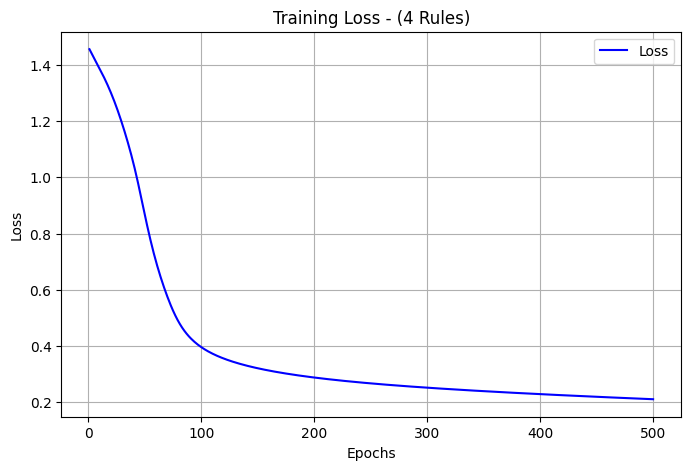

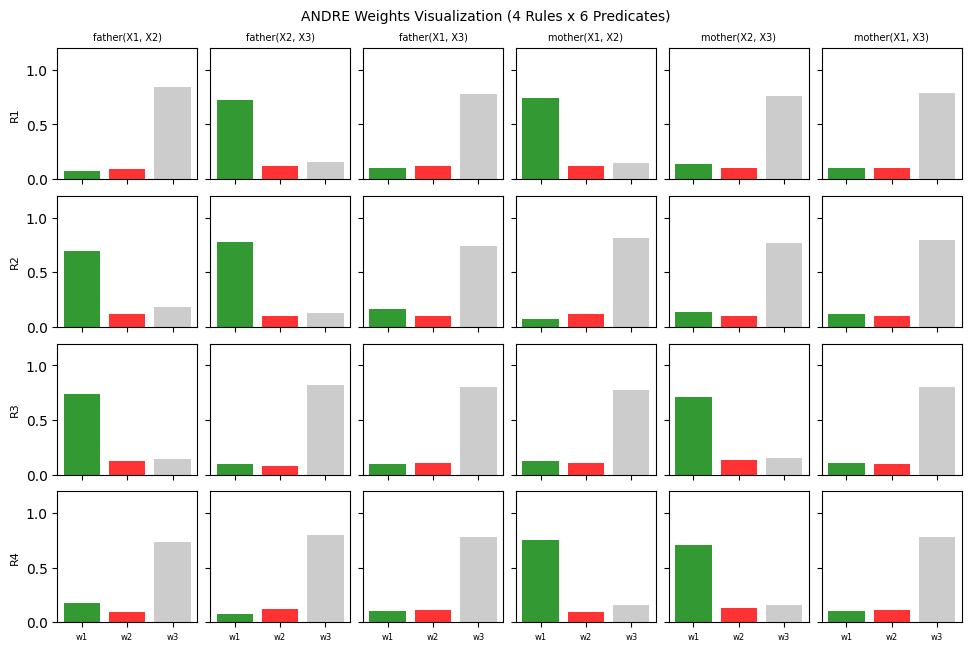

Extracted Rule: grandparent(X1, X3) :- father(X2, X3) and mother(X1, X2).
Extracted Rule: grandparent(X1, X3) :- father(X1, X2) and father(X2, X3).
Extracted Rule: grandparent(X1, X3) :- father(X1, X2) and mother(X2, X3).
Extracted Rule: grandparent(X1, X3) :- mother(X1, X2) and mother(X2, X3).

Final Rule:
h :- father(X2, X3) and mother(X1, X2) OR father(X1, X2) and father(X2, X3) OR father(X1, X2) and mother(X2, X3) OR mother(X1, X2) and mother(X2, X3).


In [ ]:
# Cosine similarity function
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_hard_metric = -float('inf')
best_losses = []

# Move data to device
# X_train = X_train.to(device)
# y_train = y_train.to(device)

# for num_rules in range(Num_rules):
for num_rules in [3]:

    for restart in range(num_restarts):
        model = ANDRE(num_rules + 1, pot_body_pred_dim=input_dim, variable_matrix=variable_matrix if structured_data else None, lr=0.005, weight_decay=1e-4)
        model = model

        losses_andre = []

        for epoch in range(num_epochs):
            model.train()

            # Shuffle dataset
            perm = torch.randperm(num_samples)
            X_train_shuffled = X_train[perm]
            y_train_shuffled = y_train[perm]

            epoch_loss = 0.0

            # Mini-batch training loop
            for i in range(0, num_samples, batch_size):
                xb = X_train_shuffled[i:i + batch_size]
                yb = y_train_shuffled[i:i + batch_size]

                model.optimizer.zero_grad()
                outputs = model(xb).squeeze()

                # Binary Cross-Entropy Loss
                bce_loss = model.criterion(outputs, yb)

                # Similarity Penalty
                sim_loss = 0.0
                for i in range(num_rules + 1):
                    wi = model.saved_weights[i].view(input_dim, -1)
                    for j in range(i + 1, num_rules + 1):
                        wj = model.saved_weights[j].view(input_dim, -1)
                        sim_loss += nn.CosineSimilarity(dim=1)(wi, wj).mean()
                sim_loss = sim_loss / (num_rules + 1)

                if structured_data:
                    M = model.M_matrices
                    M_head = [M[i][head_vars] for i in range(num_rules + 1)]
                    head_var_probs = torch.prod(torch.stack(M_head), dim=0)

                    # Range Restriction Loss
                    rr_loss_1 = nn.MSELoss()(head_var_probs, torch.ones_like(head_var_probs))
                    rr_loss_2 = nn.MSELoss()(head_var_probs, torch.ones_like(head_var_probs))
                    rr_loss = rr_loss_1 + rr_loss_2
                    rr_loss = rr_loss.sum() / xb.size(0)

                    # Connectivity Loss
                    M_connected = [M[i][connected_vars] for i in range(num_rules + 1)]
                    Sum_Fx = sum(torch.exp(-0.5 * ((M - 1.0) / 0.2)**2) / (0.2 * math.sqrt(2 * math.pi)) for M in M_connected)
                    conn_loss_1 = 0.5 * Sum_Fx / len(M_connected)
                    conn_loss_2 = nn.MSELoss()(conn_loss_1, 2 * torch.ones_like(conn_loss_1))
                    conn_loss = conn_loss_1 + conn_loss_2
                    conn_loss = conn_loss.sum() / xb.size(0)

                    # Entropy Loss
                    entropy_term = sum(model.entropies)
                    entropy_term = entropy_term / xb.size(0)

                    # Total Loss
                    total_loss = bce_loss + ent_weight * entropy_term + rr_weight * rr_loss + conn_weight * conn_loss
                    # print("bce_loss", bce_loss.item(), "entropy_term:", entropy_term.item(), "rr_loss:", rr_loss.item(), 
                    #       "conn_loss:", conn_loss.item(), "penalty:", sim_loss.item())

                else:
                    entropy_term = sum(model.entropies)
                    total_loss = bce_loss + ent_weight * entropy_term

                total_loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                model.optimizer.step()

                epoch_loss += total_loss.item()

            model.scheduler.step()
            losses_andre.append(epoch_loss)
            # print(f"Num Rules: {num_rules + 1}, Restart {restart+1}/{num_restarts}, Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.4f}.")

        # Evaluate model
        metrics = model.evaluate(X_train, y_train)
        accuracy = metrics['accuracy']
        precision = metrics['precision']
        recall = metrics['recall']
        f1_score = metrics['f1_score']

        # hard_metric = 0.25 * (accuracy + precision + recall + f1_score)
        hard_metric = accuracy * precision * recall

        print(f"Num Rules: {num_rules + 1}, Restart {restart+1}/{num_restarts}, Hard Metric: {hard_metric:.4f}.")
        if best_hard_metric < hard_metric:
            print(f"New best model found with {num_rules + 1} rules and hard metric {hard_metric:.4f}.")
            best_hard_metric = hard_metric
            best_state_dict = deepcopy(model.state_dict())
            best_losses = losses_andre
            best_num_rules = num_rules + 1

            acc = metrics['accuracy']
            print(f"Restart {restart+1}: acc_ratio = {acc:.4f}")
            if acc > acc_threshold:
                print(f"The accuracy threshold of {acc_threshold} has been reached. Stopping further restarts.")
                break

# Load the best model
best_model = ANDRE(best_num_rules, pot_body_pred_dim=input_dim, variable_matrix=variable_matrix if structured_data else None, lr=0.005, weight_decay=1e-4)
best_model.load_state_dict(best_state_dict)

# Evaluate best model
best_model.print_evaluation(X_train, y_train)

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss - ({best_num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_andre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        # weights = torch.sigmoid(neuron.raw_weights).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_andre.append(rule_weights)
# print("\nFinal Weights of the Network:")
# for i, weights in enumerate(Weights_andre):
#     print(f"Rule {i+1}: {weights}")

if visualize_weights:
    plot_andre_weights(Weights_andre, input_dim=input_dim, predicates=body_predicates, structured_data=structured_data)

# Rule interpretation
final_rule = extract_rules(Weights_andre=Weights_andre, X_train=X_train, 
                           dataset_type=dataset_type, body_predicates=body_predicates,
                           head_predicate=head_predicate)
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


### Sort Rules by Accuracy

In [14]:
# Extract and evaluate individual rules, then sort by accuracy

def evaluate_single_rule(rule_weights, X_data, y_data, variable_matrix=None):
    """
    Create a single-rule ANDRE model and evaluate its accuracy.
    
    Args:
        rule_weights: List of weights for all neurons in the rule
        X_data: Input features
        y_data: True labels
        input_dim: Number of input dimensions
        variable_matrix: Variable matrix for structured data
        
    Returns:
        Dictionary with accuracy and other metrics
    """

    # Find x_data columns as input_dim
    input_dim = X_data.shape[1]

    # Create single-rule ANDRE model
    single_rule_model = ANDRE(num_rules=1, pot_body_pred_dim=input_dim, 
                              variable_matrix=variable_matrix, lr=0.005, weight_decay=1e-4)
    
    # Load the weights for this single rule
    with torch.no_grad():
        for neuron_idx, neuron in enumerate(single_rule_model.rules[0]):
            # Convert weights back to raw_weights (inverse of softmax)
            weights_tensor = torch.tensor(rule_weights[neuron_idx], dtype=torch.float32)
            # Use log to approximate inverse softmax
            neuron.raw_weights.data = torch.log(weights_tensor + 1e-10)
    
    # Evaluate the single rule
    single_rule_model.eval()
    metrics = single_rule_model.evaluate(X_data, y_data)
    
    return metrics


# Evaluate each rule individually
print("\n" + "="*70)
print("INDIVIDUAL RULE EVALUATION")
print("="*70)

rule_evaluations = []

for rule_idx, rule_weights in enumerate(Weights_andre):
    print(f"\nEvaluating Rule {rule_idx + 1}...")
    
    # Evaluate this rule
    metrics = evaluate_single_rule(
        rule_weights, 
        X_train, 
        y_train, 
        variable_matrix if structured_data else None
    )
    
    # Extract the rule text
    if dataset_type == "binary":
        preds = interpret_neuron_weights(body_preds=body_predicates, Weights=rule_weights)
    else:
        # For probabilistic, use a representative sample
        sample_pred_values = X_train[0].numpy()
        preds = interpret_neuron_weights_entropy(sample_pred_values, rule_weights)
    
    refined_preds = [pred for pred in preds if pred != '1' and pred != '?']
    rule_text = " and ".join(refined_preds) if refined_preds else "true"
    
    # Store evaluation results
    rule_evaluations.append({
        'rule_idx': rule_idx + 1,
        'rule_text': rule_text,
        'accuracy': metrics['accuracy'],
        'precision': metrics['precision'],
        'recall': metrics['recall'],
        'f1_score': metrics['f1_score'],
        'roc_auc': metrics['roc_auc'],
        'weights': rule_weights
    })
    
    print(f"Rule {rule_idx + 1}: {rule_text}")
    print(f"  Accuracy: {metrics['accuracy']:.4f}, Precision: {metrics['precision']:.4f}, "
          f"Recall: {metrics['recall']:.4f}, F1: {metrics['f1_score']:.4f}")

# Sort rules by accuracy (descending)
sorted_rules = sorted(rule_evaluations, key=lambda x: x['accuracy'], reverse=True)

# Display sorted results
print("\n" + "="*70)
print("RULES SORTED BY ACCURACY (Best to Worst)")
print("="*70)

for rank, rule_info in enumerate(sorted_rules, 1):
    print(f"\nRank {rank}: Rule {rule_info['rule_idx']}")
    print(f"  Formula: {head_predicate} :- {rule_info['rule_text']}")
    print(f"  Accuracy:  {rule_info['accuracy']:.4f}")
    print(f"  Precision: {rule_info['precision']:.4f}")
    print(f"  Recall:    {rule_info['recall']:.4f}")
    print(f"  F1-Score:  {rule_info['f1_score']:.4f}")
    print(f"  ROC-AUC:   {rule_info['roc_auc']:.4f}")

print("\n" + "="*70)

# Create final sorted rule set
sorted_rule_formulas = [f"{rule_info['rule_text']}" for rule_info in sorted_rules]
final_sorted_rule = f"{head_predicate} :- " + " OR ".join(sorted_rule_formulas) + "."

print("\nFINAL RULE (sorted by individual accuracy):")
print(final_sorted_rule)
print("="*70)


INDIVIDUAL RULE EVALUATION

Evaluating Rule 1...
Rule 1: father(X2, X3) and mother(X1, X2)
  Accuracy: 0.6250, Precision: 1.0000, Recall: 0.3239, F1: 0.4894

Evaluating Rule 2...
Rule 2: father(X1, X2) and father(X2, X3)
  Accuracy: 0.7188, Precision: 1.0000, Recall: 0.4930, F1: 0.6604

Evaluating Rule 3...
Rule 3: father(X1, X2) and mother(X2, X3)
  Accuracy: 0.6875, Precision: 1.0000, Recall: 0.4366, F1: 0.6078

Evaluating Rule 4...
Rule 4: mother(X1, X2) and mother(X2, X3)
  Accuracy: 0.6797, Precision: 1.0000, Recall: 0.4225, F1: 0.5941

RULES SORTED BY ACCURACY (Best to Worst)

Rank 1: Rule 2
  Formula: grandparent(X1, X3) :- father(X1, X2) and father(X2, X3)
  Accuracy:  0.7188
  Precision: 1.0000
  Recall:    0.4930
  F1-Score:  0.6604
  ROC-AUC:   0.7504

Rank 2: Rule 3
  Formula: grandparent(X1, X3) :- father(X1, X2) and mother(X2, X3)
  Accuracy:  0.6875
  Precision: 1.0000
  Recall:    0.4366
  F1-Score:  0.6078
  ROC-AUC:   0.7015

Rank 3: Rule 4
  Formula: grandparent(X1,

#### Curriculum Learning (Not Effective)


Learning Rule #1
Num Rules: 1, Restart 1/3, Final Loss: 16.8795.
Restart 1: acc_ratio = 0.6538
Num Rules: 1, Restart 2/3, Final Loss: 17.0158.
Restart 2: acc_ratio = 0.6615
Num Rules: 1, Restart 3/3, Final Loss: 16.8629.
Restart 3: acc_ratio = 0.6280
Best acc_ratio for Rule 1: 0.6615

Learning Rule #2
Num Rules: 2, Restart 1/3, Final Loss: 14.1450.
Restart 1: acc_ratio = 0.7035
Num Rules: 2, Restart 2/3, Final Loss: 14.1398.
Restart 2: acc_ratio = 0.7003
Num Rules: 2, Restart 3/3, Final Loss: 14.1534.
Restart 3: acc_ratio = 0.7003
Best acc_ratio for Rule 2: 0.7035

Learning Rule #3
Num Rules: 3, Restart 1/3, Final Loss: 11.7571.
Restart 1: acc_ratio = 0.8015
Num Rules: 3, Restart 2/3, Final Loss: 14.4542.
Restart 2: acc_ratio = 0.7415
Num Rules: 3, Restart 3/3, Final Loss: 11.7952.
Restart 3: acc_ratio = 0.7757
Best acc_ratio for Rule 3: 0.8015
Stopping curriculum learning as acc_ratio threshold met.


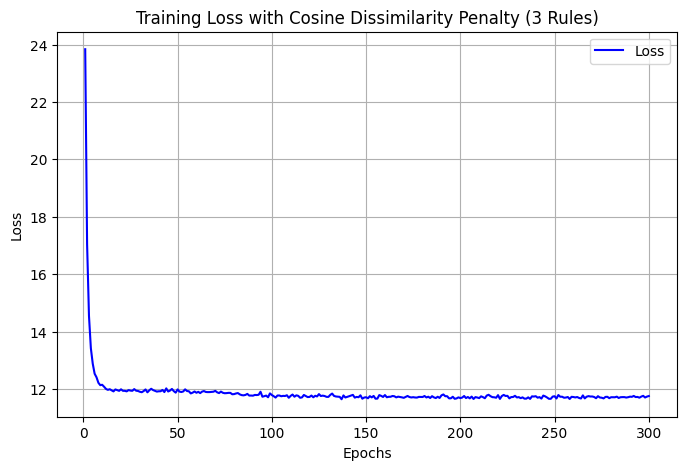


Final M matrices:
M1: [1. 2. 1.]
M2: [1. 2. 1.]
M3: [1. 2. 1.]
The most repeated rule is: 'h1 :- ? and ? and ? and ?.'
Accuracy over training data: 1.0.
The most repeated rule is: 'h2 :- ? and ?.'
Accuracy over training data: 1.0.
The most repeated rule is: 'h3 :- ? and ?.'
Accuracy over training data: 1.0.

Final Rule:
target(X1, X3) :- ? and ? and ? and ? OR ? and ? OR ? and ?.


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from ANDRE_Net import ANDRE
from utils import create_V_matrix, interpret_neuron_weights_entropy_, compute_acc_ratio_all_rules_attention
import math
from collections import Counter

# Target body body_predicates and their variables
# We assume the model doesn't know the variables of the body_predicates beforehand, so we want to learn them
body_predicates = ["father(X1, X2)", "father(X2, X3)", "father(X1, X3)", "mother(X1, X2)", "mother(X2, X3)", "mother(X1, X3)"]

# Define predicate-variable binary matrix 
# Here the variables are known for each predicate
# update variable_matrix to match the body_predicates ["father(X1, X2)", "father(X2, X3)", "father(X1, X3)", 
# "mother(X1, X2)", "mother(X2, X3)", "mother(X1, X3)""]

variable_matrix, variables = create_V_matrix(body_predicates)

# Set random seed for reproducibility
torch.manual_seed(42)
input_dim = 6  # Number of features in X_train
num_neurons_per_rule = input_dim  # Number of neurons per rule
num_samples = 4000  # For testing, we can use a smaller number of samples

# X_train = (torch.rand(num_samples, input_dim) > 0.5).float()  # Random binary features
X_train = (torch.rand(num_samples, input_dim) > 0.5).float()
# perturb data
X_train = X_train + 0.1 * torch.randn_like(X_train)
# clip to [0, 1]
X_train = torch.clamp(X_train, 0.0, 1.0)

y_train = (((X_train[:, 0] > 0.5) & (X_train[:, 1] > 0.5)) | 
           ((X_train[:, 0] > 0.5) & (X_train[:, 4] > 0.5)) | 
           ((X_train[:, 3] > 0.5) & (X_train[:, 4] > 0.5)) | 
           ((X_train[:, 3] > 0.5) & (X_train[:, 1] > 0.5))).float()
# Setup
X_tensor = X_train
y_tensor = y_train
input_dim = X_tensor.shape[1]
num_neurons_per_rule = input_dim
# Define head and connected variables
head_vars = [0, 2]
connected_vars = [1]
num_epochs = 300
num_restarts = 3
batch_size = 128
max_rules = 4
acc_threshold = 0.8
sim_weight, ent_weight, rr_weight, conn_weight = 0.01, 0.01, 0.1, 0.1

frozen_state_dicts = []
best_rules_models = []

best_loss = float('inf')
best_losses = []

# Curriculum Learning Loop
for rule_idx in range(max_rules):
    print(f"\nLearning Rule #{rule_idx+1}")
    best_acc_ratio = -1.0
    best_state_dict = None
    best_model = None
    best_loss = np.inf

    for restart in range(num_restarts):
        num_rules = rule_idx + 1
        model = ANDRE(num_rules, pot_body_pred_dim=input_dim, variable_matrix=variable_matrix)

        if rule_idx > 0:
            with torch.no_grad():
                for i, rule in enumerate(model.rules[:-1]):
                    for j, neuron in enumerate(rule):
                        neuron.raw_weights.copy_(frozen_state_dicts[i][j])
                        neuron.raw_weights.requires_grad = False

        optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=0.01)
        criterion = nn.BCELoss()
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

        losses = []
        for epoch in range(num_epochs):

            # Shuffle dataset
            perm = torch.randperm(num_samples)
            X_train_shuffled = X_train[perm]
            y_train_shuffled = y_train[perm]

            epoch_loss = 0.0

            # Mini-batch training loop
            for i in range(0, num_samples, batch_size):
                xb = X_train_shuffled[i:i + batch_size]
                yb = y_train_shuffled[i:i + batch_size]

                optimizer.zero_grad()
                outputs = model(xb).squeeze()
                bce_loss = criterion(outputs, yb)

                penalty = 0.0
                for i in range(rule_idx + 1):
                    for j in range(i + 1, rule_idx + 1):
                        wi = model.saved_weights[i].view(num_neurons_per_rule, -1)
                        wj = model.saved_weights[j].view(num_neurons_per_rule, -1)
                        penalty += nn.CosineSimilarity(dim=1)(wi, wj).mean()

                M = model.M_matrices
                M_head = [M[i][head_vars] for i in range(rule_idx + 1)]
                head_var_probs = torch.prod(torch.stack(M_head), dim=0)
                rr_loss_1 = nn.MSELoss()(head_var_probs, torch.ones_like(head_var_probs))

                # Find the MSE of the head variable probabilities with 1
                rr_loss_2 = nn.MSELoss()(head_var_probs, torch.ones_like(head_var_probs))
                rr_loss = rr_loss_1 + rr_loss_2
                rr_loss = rr_loss.sum()

                M_connected = [M[i][connected_vars] for i in range(rule_idx + 1)]
                Sum_Fx = sum(torch.exp(-0.5 * ((M - 1.0) / 0.2)**2) / (0.2 * math.sqrt(2 * math.pi)) for M in M_connected)
                conn_loss = 0.5 * Sum_Fx / len(M_connected)

                entropy_term = sum(model.entropies)
                # total_loss = bce_loss + sim_weight * penalty - ent_weight * entropy_term + rr_weight * rr_loss + conn_weight * conn_loss
                total_loss = bce_loss + ent_weight * entropy_term + rr_weight * rr_loss + conn_weight * conn_loss

                total_loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

                epoch_loss += total_loss.item()

            scheduler.step()

            losses.append(epoch_loss)

        final_loss = losses[-1]
        print(f"Num Rules: {num_rules}, Restart {restart+1}/{num_restarts}, Final Loss: {final_loss:.4f}.")
        if final_loss < best_loss:
            best_loss = final_loss
            # best_state_dict_loss = deepcopy(model.state_dict())
            best_losses = losses

        acc = compute_acc_ratio_all_rules_attention(model, X_tensor, y_tensor)
        print(f"Restart {restart+1}: acc_ratio = {acc:.4f}")
        if acc > best_acc_ratio:
            best_acc_ratio = acc
            best_state_dict = [neuron.raw_weights.detach().clone() for neuron in model.rules[rule_idx]]
            # Save the model's state_dict instead of deepcopy
            best_model_state = model.state_dict()
            best_num_rules = rule_idx + 1

        # for i in range(rule_idx + 1):
        #     rule_acc_ratio = compute_acc_ratio(model, X_tensor, y_tensor, i)
        #     print(f"Rule {rule_idx+1} Restart {restart+1}: acc_ratio = {rule_acc_ratio:.4f}")
    frozen_state_dicts.append(best_state_dict)
    # Recreate the model and load the best state_dict
    best_model = ANDRE(num_rules, pot_body_pred_dim=input_dim, variable_matrix=variable_matrix)
    best_model.load_state_dict(best_model_state)
    best_rules_models.append(best_model)
    print(f"Best acc_ratio for Rule {rule_idx+1}: {best_acc_ratio:.4f}")
    if best_acc_ratio >= acc_threshold:
        print("Stopping curriculum learning as acc_ratio threshold met.")
        break
# Load best model and compute M
# Use best_num_rules to match the state_dict
best_model = ANDRE(best_num_rules, pot_body_pred_dim=input_dim, variable_matrix=variable_matrix)

# Filter out keys that are not in the model's state_dict
model_keys = set(best_model.state_dict().keys())
best_model.load_state_dict(best_model_state)

_ = best_model(X_tensor)

# Output M matrices
M_outputs = [M.detach().numpy().tolist() for M in best_model.M_matrices]

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_andre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(5*neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_andre.append(rule_weights)

print("\nFinal M matrices:")
for i, M in enumerate(M_outputs):
    print(f"M{i+1}: {np.round(M)}")


Predicate_values = X_tensor

Final_rules = []
for rule_num, weights in enumerate(Weights_andre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        # preds = interpret_neuron_weights_(pred_values, weights)
        preds = interpret_neuron_weights_entropy_(body_predicates, pred_values, weights, entropy_threshold=0.2)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "target(X1, X3) :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")

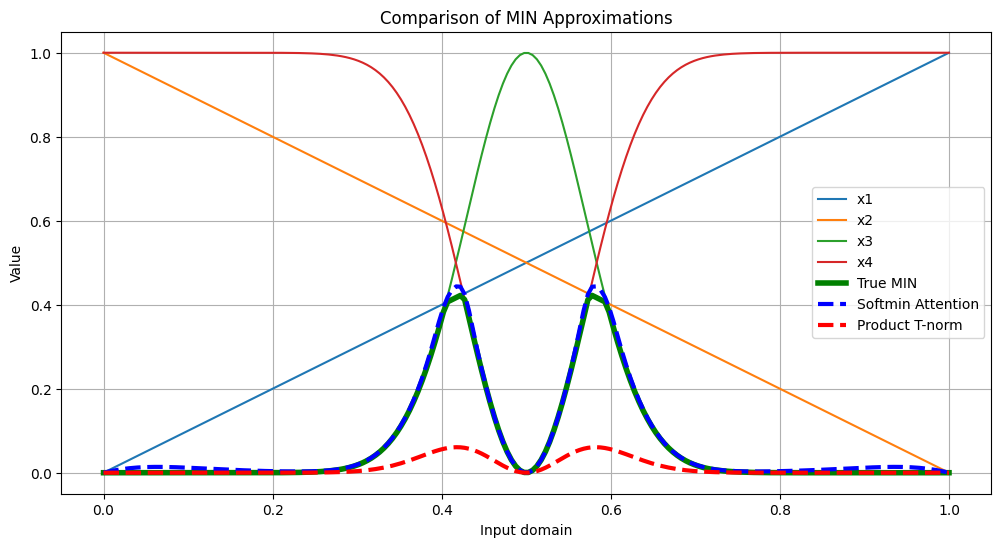

In [2]:
import torch
import matplotlib.pyplot as plt
import numpy as np

# Define input domain
x = torch.linspace(0, 1, 200)

# Define 4 fuzzy membership functions with different shapes
x1 = x  # Linear increasing
x2 = 1 - x  # Linear decreasing
x3 = torch.exp(-((x - 0.5) ** 2) / 0.01)  # Gaussian centered at 0.5
x4 = 1 - torch.exp(-((x - 0.5) ** 2) / 0.01)  # Gaussian centered at 0.5

# Stack them as rows
X = torch.stack([x1, x2, x3, x4], dim=0)

# True element-wise min across the 4 functions
min_vals = torch.min(X, dim=0).values

# Softmin attention approximation
def softmin_attention(x_tensor, beta=20.0):
    scores = -beta * x_tensor
    weights = torch.softmax(scores, dim=0)
    return (weights * x_tensor).sum(dim=0)

softmin_vals = torch.stack([softmin_attention(X[:, i]) for i in range(X.shape[1])])

# Product t-norm approximation
prod_vals = torch.prod(X, dim=0)

# Plotting
plt.figure(figsize=(12, 6))
plt.plot(x, X.T, label=['x1', 'x2', 'x3', 'x4'], linewidth=1.5)
plt.plot(x, min_vals, label='True MIN', linewidth=4, color='green')
plt.plot(x, softmin_vals, label='Softmin Attention', linestyle='--', linewidth=3, color='blue')
plt.plot(x, prod_vals, label='Product T-norm', linestyle='--', linewidth=3, color='red')
plt.title("Comparison of MIN Approximations")
plt.xlabel("Input domain")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.show()

# Show some example values for comparison
sample_df = {
    "x": x.numpy()[::20],
    "min": min_vals.numpy()[::20],
    "softmin": softmin_vals.numpy()[::20],
    "product": prod_vals.numpy()[::20],
}


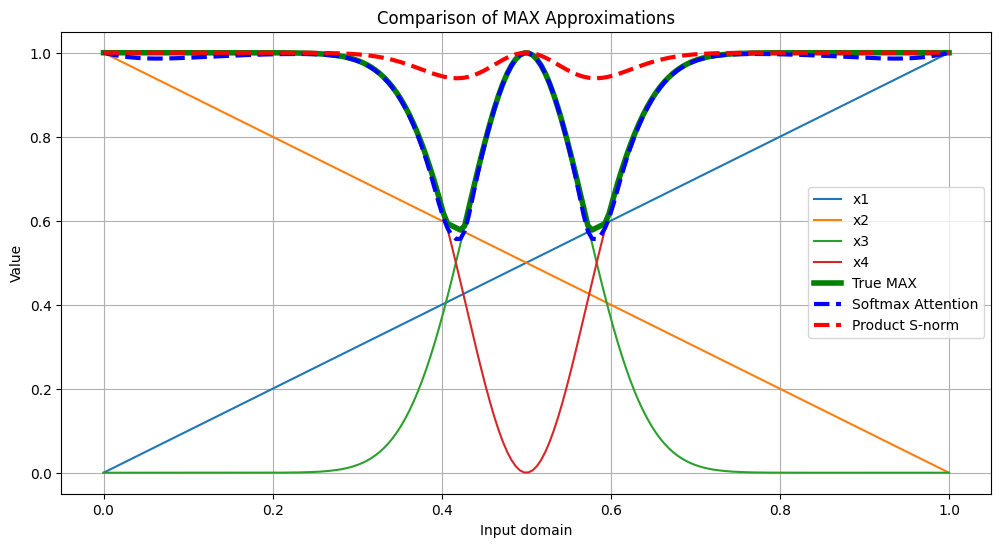

In [25]:
import torch
import matplotlib.pyplot as plt
import numpy as np

# Define input domain
x = torch.linspace(0, 1, 200)

# Define 4 fuzzy membership functions with different shapes
x1 = x  # Linear increasing
x2 = 1 - x  # Linear decreasing
x3 = torch.exp(-((x - 0.5) ** 2) / 0.01)  # Gaussian centered at 0.5
x4 = 1 - torch.exp(-((x - 0.5) ** 2) / 0.01)  # Gaussian centered at 0.5

# Stack them as rows
X = torch.stack([x1, x2, x3, x4], dim=0)

# True element-wise min across the 4 functions
min_vals = torch.max(X, dim=0).values

# Softmax attention approximation
def softmax_attention(x_tensor, beta=20.0):
    scores = beta * x_tensor
    weights = torch.softmax(scores, dim=0)
    return (weights * x_tensor).sum(dim=0)

softmax_vals = torch.stack([softmax_attention(X[:, i]) for i in range(X.shape[1])])

# find OR using product t-norm approximation and demorgan law
or_vals = 1 - torch.prod(1 - X, dim=0)

# Product t-norm approximation
# prod_vals = torch.prod(X, dim=0)

# Plotting
plt.figure(figsize=(12, 6))
plt.plot(x, X.T, label=['x1', 'x2', 'x3', 'x4'], linewidth=1.5)
plt.plot(x, min_vals, label='True MAX', linewidth=4, color='green')
plt.plot(x, softmax_vals, label='Softmax Attention', linestyle='--', linewidth=3, color='blue')
plt.plot(x, or_vals, label='Product S-norm', linestyle='--', linewidth=3, color='red')
plt.title("Comparison of MAX Approximations")
plt.xlabel("Input domain")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.show()

# Show some example values for comparison
sample_df = {
    "x": x.numpy()[::20],
    "min": min_vals.numpy()[::20],
    "softmin": softmin_vals.numpy()[::20],
    "product": prod_vals.numpy()[::20],
}


## Propositionalization

In [ ]:
import itertools
import numpy as np

# Define constants
NUM_DIGITS = 10
VARIABLES = ['X', 'V1', 'V2']
body_predicates = ['zero', 'successor']
VARIABLE_DEPTH = 2  # Number of extra variables beyond the target argument

# Generate background knowledge
B = set()
B.add(('zero', (0,)))
for i in range(NUM_DIGITS - 1):
    B.add(('successor', (i, i + 1)))

# Generate positive and negative examples
P = set(i for i in range(NUM_DIGITS) if i % 2 == 0)  # even numbers
N = set(i for i in range(NUM_DIGITS) if i % 2 == 1)  # odd numbers

# All constants (digits)
constants = list(range(NUM_DIGITS))

# Generate all substitutions: (X, V1, V2)
substitutions = list(itertools.product(constants, repeat=len(VARIABLES)))

# Generate body features (all applications of zero() or successor())
body_features = []
for pred in body_predicates:
    if pred == 'zero':
        for var in VARIABLES:
            body_features.append((pred, (var,)))
    elif pred == 'successor':
        for var1 in VARIABLES:
            for var2 in VARIABLES:
                body_features.append((pred, (var1, var2)))

# Feature index mapping
feature_to_idx = {feat: i for i, feat in enumerate(body_features)}
num_features = len(body_features)

# Propositionalization
dataset = []

for substitution in substitutions:
    var_map = dict(zip(VARIABLES, substitution))
    vi = np.zeros(num_features)
    
    for i, (pred, args) in enumerate(body_features):
        grounded_args = tuple(var_map[arg] for arg in args)
        if (pred, grounded_args) in B:
            vi[i] = 1

    x_val = var_map['X']
    vo = 1 if x_val in P else 0

    if np.sum(vi) > 0:
        dataset.append((vi, vo))

# Convert to arrays
X_data = np.array([vi for vi, vo in dataset])
y_data = np.array([vo for vi, vo in dataset])

# Display sample
print("Sample Input Feature Vector:", X_data[0])
print("Sample Output Label:", y_data[0])
print("Total Examples:", len(X_data))


Sample Input Feature Vector: [1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Sample Output Label: 1
Total Examples: 613
